# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [4]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [5]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Wgraj plik szkolnictwo_wysze.csv:


Saving szkolnictwo_wysze.csv to szkolnictwo_wysze.csv


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [6]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

﻿name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [7]:
# TODO: wczytaj plik do ramki `df` z właściwym separatorem
df = pd.read_csv(PLIK_LODZ,sep=";")

# TODO: wyświetl pierwsze wiersze, wymiary i typy kolumn
print(df.head(),'\n')
print(df.shape,'\n')
print(df.dtypes)


                 name   rok  wartość   zmienna
0  Szkolnictwo wyższe  2012       22  uczelnie
1  Szkolnictwo wyższe  2013       22  uczelnie
2  Szkolnictwo wyższe  2014       23  uczelnie
3  Szkolnictwo wyższe  2015       21  uczelnie
4  Szkolnictwo wyższe  2016       20  uczelnie 

(65, 4) 

name       object
rok         int64
wartość     int64
zmienna    object
dtype: object


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:* Separator to `;`, kolumna `wartość` ma typ liczbowy `int64`, nazwy polskie wczytują się poprawnie.

## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [8]:
# TODO: jakie są zmienne i ile mają wierszy?
print(df['zmienna'].value_counts())


# TODO: format szeroki (pivot) — wynik zapisz w `szeroka`
szeroka = pd.pivot_table(df, values='wartość', index='rok', columns='zmienna',aggfunc='sum')
szeroka

zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
rok,,,,,
2012,24825,55265,36281,91546,22
2013,22590,50007,33464,83471,22
2014,21343,48220,32456,80676,23
2015,19835,45584,30769,76353,21
2016,17662,44053,29908,73961,20
2017,19281,42990,29029,72019,22
2018,17046,39312,26253,65565,20
2019,15819,38146,26297,64443,19
2020,14082,39170,26155,65325,18


## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [9]:
# TODO: policz różnicę (kobiety + mężczyźni) − ogółem dla każdego roku
for row in szeroka.iterrows():
  print(row[0],row[1]['ogółem']-row[1]['kobiety']-row[1]['mężczyźni'])

2012 0
2013 0
2014 0
2015 0
2016 0
2017 0
2018 0
2019 0
2020 0
2021 0
2022 0
2023 0
2024 0


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [10]:
# TODO: statystyki opisowe
describe = szeroka.describe()
display(describe)

# TODO: zmiana procentowa 2012 → 2024
print("Zmiana procentowa 2012 -> 2024:")
for col in szeroka.columns:
    wartosc_2012 = szeroka.loc[2012, col]
    wartosc_2024 = szeroka.loc[2024, col]
    zmiana_proc = ((wartosc_2024 - wartosc_2012) / wartosc_2012) * 100
    print(f"{col:<25}: {zmiana_proc:+.2f}%")

# TODO: nowe kolumny
szeroka['udzial_kobiet'] = szeroka['kobiety'] / szeroka['ogółem']
szeroka['studenci_na_uczelnie'] = szeroka['ogółem'] / szeroka['uczelnie']

print("\nNowe kolumny w ramce szeroka:")
display(szeroka[['udzial_kobiet', 'studenci_na_uczelnie']].head())

zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
count,13.00,13.00,13.00,13.00,13.00
mean,17780.54,43010.92,28793.92,71804.85,19.54
std,3522.40,5391.05,3524.63,8900.65,2.44
min,14082.00,38146.00,25710.00,64272.00,15.00
25%,14756.00,39170.00,26049.00,65297.00,18.00
50%,17046.00,39958.00,26297.00,66002.00,20.00
75%,19835.00,45584.00,30769.00,76353.00,22.00
max,24825.00,55265.00,36281.00,91546.00,23.00


Zmiana procentowa 2012 -> 2024:
absolwenci ogółem        : -41.29%
kobiety                  : -30.22%
mężczyźni                : -29.14%
ogółem                   : -29.79%
uczelnie                 : -31.82%

Nowe kolumny w ramce szeroka:


zmienna,udzial_kobiet,studenci_na_uczelnie
rok,,
2012,0.60,4161.18
2013,0.60,3794.14
2014,0.60,3507.65
2015,0.60,3635.86
2016,0.60,3698.05


## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

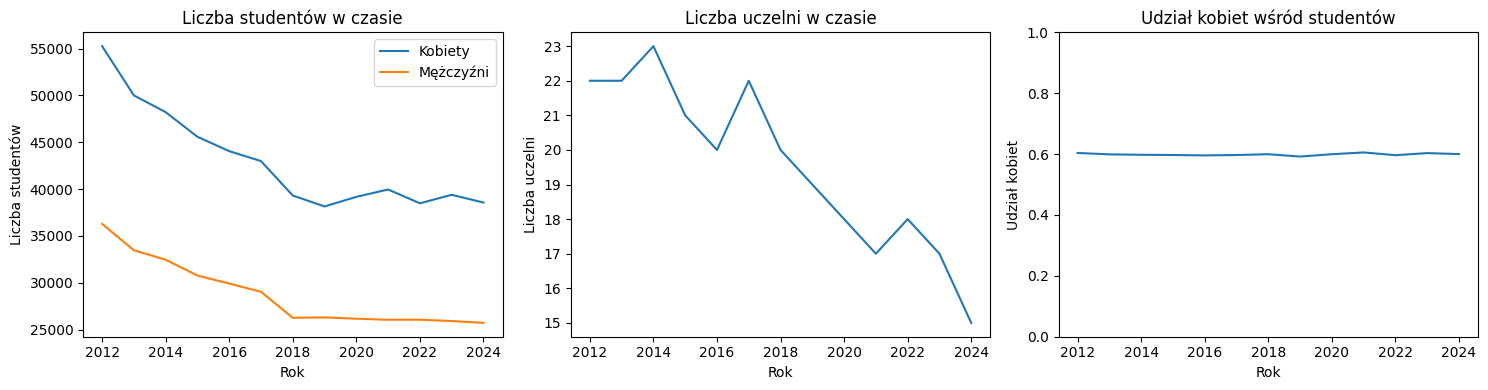

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# TODO: wykres 1 — kobiety i mężczyźni
plt.subplot(1,3,1)
szeroka[['kobiety','mężczyźni']].plot(kind='line', ax=axes[0])
axes[0].set_title('Liczba studentów w czasie')
axes[0].set_xlabel('Rok')
axes[0].set_ylabel('Liczba studentów')
axes[0].legend(['Kobiety', 'Mężczyźni'])

# TODO: wykres 2 — uczelnie
plt.subplot(1,3,2)
szeroka['uczelnie'].plot(kind='line', ax=axes[1])
axes[1].set_title('Liczba uczelni w czasie')
axes[1].set_xlabel('Rok')
axes[1].set_ylabel('Liczba uczelni')

# TODO: wykres 3 — udział kobiet
plt.subplot(1,3,3)
szeroka['udzial_kobiet'].plot(kind='line', ax=axes[2])
axes[2].set_title('Udział kobiet wśród studentów')
axes[2].set_xlabel('Rok')
axes[2].set_ylabel('Udział kobiet')
axes[2].set_ylim(0, 1)


plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:* Zmniejszyła się liczba studentów i uczelni.

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** Likwidacja dzikich wysypisk.csv · **link:** https://otwarte.miasto.lodz.pl/ekologia/ · **data pobrania:** 22 października 2026

In [12]:
# TODO: wczytanie i przegląd Twojego zbioru
LODZ_WYSYPISKA = "likwidacja_dzikich_wysypisk.csv"
upewnij_sie_ze_jest(LODZ_WYSYPISKA)

with open(LODZ_WYSYPISKA, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())
    print('\n')

df = pd.read_csv(LODZ_WYSYPISKA, sep=';')
print(df, '\n')
print(df.shape, '\n')
print(df.dtypes, '\n')

print("dane są w formacie szerokim (pivot z połączonymi kolumnami name i zmienne):\n")


Wgraj plik likwidacja_dzikich_wysypisk.csv:


Saving likwidacja_dzikich_wysypisk.csv to likwidacja_dzikich_wysypisk.csv
﻿id;name;rok;wartość;zmienne
290436;Dzikie wysypiska;2008;1155;zlikwidowane - w ciągu roku
290436;Dzikie wysypiska;2009;1500;zlikwidowane - w ciągu roku
290436;Dzikie wysypiska;2010;1133;zlikwidowane - w ciągu roku
290436;Dzikie wysypiska;2011;2270;zlikwidowane - w ciągu roku


        id              name   rok  wartość                      zmienne
0   290436  Dzikie wysypiska  2008     1155  zlikwidowane - w ciągu roku
1   290436  Dzikie wysypiska  2009     1500  zlikwidowane - w ciągu roku
2   290436  Dzikie wysypiska  2010     1133  zlikwidowane - w ciągu roku
3   290436  Dzikie wysypiska  2011     2270  zlikwidowane - w ciągu roku
4   290436  Dzikie wysypiska  2012     1263  zlikwidowane - w ciągu roku
5   290436  Dzikie wysypiska  2013     2018  zlikwidowane - w ciągu roku
6   290436  Dzikie wysypiska  2014     1835  zlikwidowane - w ciągu roku
7   290436  Dzikie wysypiska  2015     3247  zlikwidowane - w c

kategoria,Dzikie wysypiska - zlikwidowane - w ciągu roku
rok,
2008,1155
2009,1500
2010,1133
2011,2270
2012,1263
2013,2018
2014,1835
2015,3247
2016,4859


Liczba brakujących wartości w oryginalnej ramce:
id           0
name         0
rok          0
wartość      0
zmienne      0
kategoria    0
dtype: int64

Liczba brakujących wartości w ramce szerokiej:
kategoria
Dzikie wysypiska - zlikwidowane - w ciągu roku    0
dtype: int64

Statystyki opisowe dla zlikwidowanych wysypisk:


kategoria,Dzikie wysypiska - zlikwidowane - w ciągu roku
count,17.00
mean,1436.00
std,1242.99
min,10.00
25%,357.00
50%,1155.00
75%,2018.00
max,4859.00


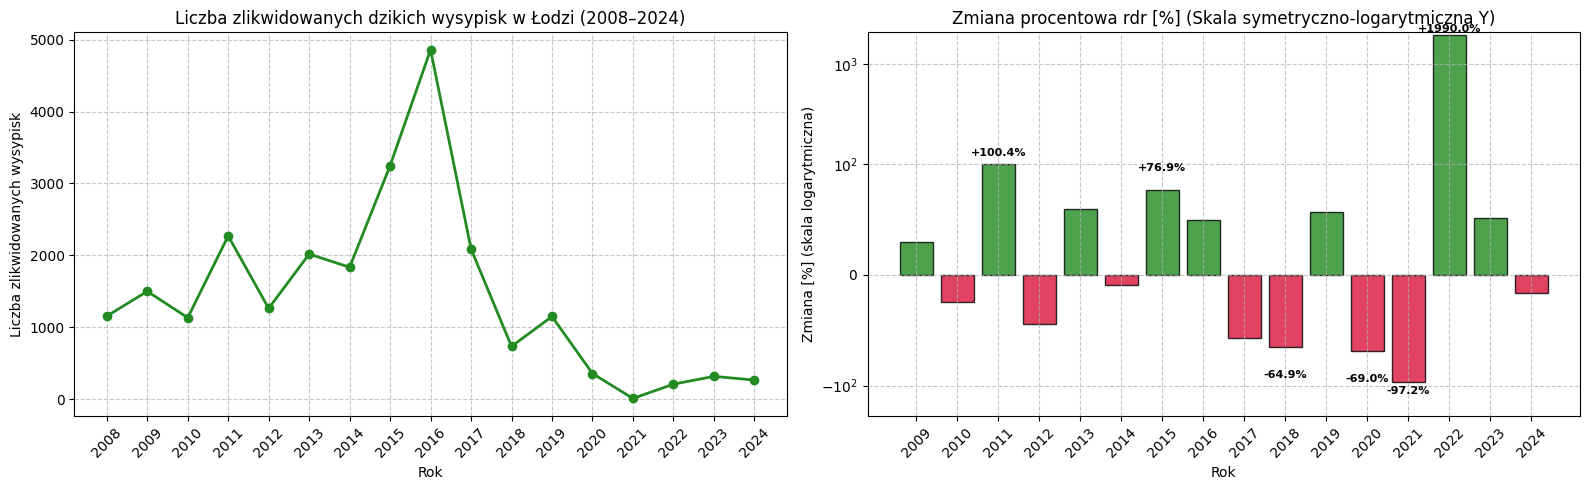

In [13]:
# 1. Przekształcenia i przygotowanie danych
df['kategoria'] = df['name'] + " - " + df['zmienne']
wysypiska_szeroki = pd.pivot_table(df, values='wartość', index='rok', columns='kategoria', aggfunc='sum')
display(wysypiska_szeroki)

# Obliczenie zmiany procentowej rok do roku
seria_wysypisk = wysypiska_szeroki.iloc[:, 0]
zmiana_rdr = seria_wysypisk.pct_change() * 100

# 2. Weryfikacja braków danych
print("Liczba brakujących wartości w oryginalnej ramce:")
print(df.isna().sum())

print("\nLiczba brakujących wartości w ramce szerokiej:")
print(wysypiska_szeroki.isna().sum())

# 3. Statystyki opisowe
print("\nStatystyki opisowe dla zlikwidowanych wysypisk:")
display(wysypiska_szeroki.describe())

# 4. Wykresy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Wykres 1: Liczba zlikwidowanych wysypisk w czasie
ax1.plot(wysypiska_szeroki.index, seria_wysypisk, marker='o', color='forestgreen', linewidth=2)
ax1.set_title("Liczba zlikwidowanych dzikich wysypisk w Łodzi (2008–2024)")
ax1.set_xlabel("Rok")
ax1.set_ylabel("Liczba zlikwidowanych wysypisk")
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.set_xticks(wysypiska_szeroki.index)
ax1.tick_params(axis='x', rotation=45)

# Wykres 2: Zmiana procentowa rok do roku (skala symlog)
kolory = ['forestgreen' if x >= 0 else 'crimson' for x in zmiana_rdr.dropna()]
bars = ax2.bar(zmiana_rdr.dropna().index, zmiana_rdr.dropna(), color=kolory, edgecolor='black', alpha=0.8)
ax2.set_title("Zmiana procentowa rdr [%] (Skala symetryczno-logarytmiczna Y)")
ax2.set_xlabel("Rok")
ax2.set_ylabel("Zmiana [%] (skala logarytmiczna)")
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.set_xticks(zmiana_rdr.dropna().index)
ax2.tick_params(axis='x', rotation=45)

# Zastosowanie skali symlog na osi Y (liniowy zakres do +/- 100, powyżej logarytmiczny)
ax2.set_yscale('symlog', linthresh=100.0)

# Dodanie wartości nad wybranymi słupkami dla czytelności
for bar, val in zip(bars, zmiana_rdr.dropna()):
    # Dodaj tekst dla największego wzrostu oraz wyraźnych spadków
    if abs(val) > 60:
        ax2.text(bar.get_x() + bar.get_width()/2.0,
                 val + (15 if val >= 0 else -30),
                 f'{val:+.1f}%',
                 ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()



```
# This is formatted as code
```

✍️ **Wnioski:** Dane w tym zbiorze mówią bardzo niewiele. Można wywnioskować, że w 2016 usunięto rekordowo dużo wysypisk. Po kilku latach usuwano ich co roku bardzo niewiele, a w 2021 zaledwie 10, co jest wartością bardzo skrajną w tym zbiorze. W roku 2022 nastąpiło nagłe ożywienie w liczbie usuwanych wysypisk.

---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [14]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()

,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

Statystyki opisowe dla wybranych cech:


,age,bmi,avg_glucose_level
count,3000.00,3000.00,3000.00
mean,45.25,26.29,134.00
std,20.83,15.88,181.27
min,0.67,-5.20,-21.40
25%,28.00,21.28,85.59
50%,49.00,24.70,101.40
75%,63.00,28.88,127.43
max,80.00,105.60,1254.60


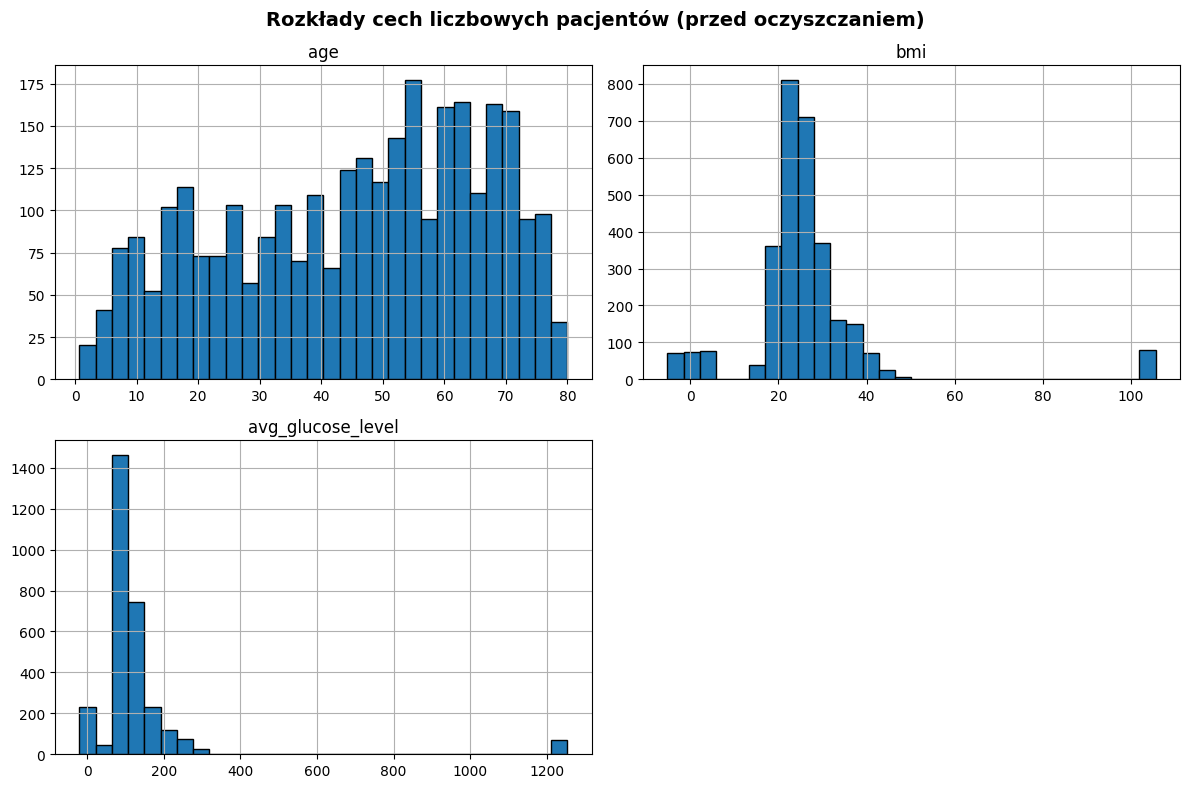

In [15]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]

# TODO: statystyki opisowe
print("Statystyki opisowe dla wybranych cech:")
display(pacjenci[LICZBOWE].describe())

# TODO: histogramy (np. pacjenci[LICZBOWE].hist(...))
pacjenci[LICZBOWE].hist(bins=30, figsize=(12, 8), edgecolor='black', grid=True)
plt.suptitle("Rozkłady cech liczbowych pacjentów (przed oczyszczaniem)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:* Wartości min i max dla wieku są możliwe. Pozostałe wartości min/max wydają sie nierealne, zwłaszcza te ujemne.

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [16]:
# TODO: maski
zle_bmi = ~pacjenci["bmi"].between(10, 60)
zla_glukoza = ~pacjenci["avg_glucose_level"].between(20, 800)
zly_wiek = ~pacjenci["age"].between(0, 120)

# TODO: liczebności
print("Liczba niemożliwych wartości w kolumnie 'bmi':", zle_bmi.sum())
print("Liczba niemożliwych wartości w kolumnie 'avg_glucose_level':", zla_glukoza.sum())
print("Liczba niemożliwych wartości w kolumnie 'age':", zly_wiek.sum())

# TODO: zamiana na NaN
pacjenci.loc[zle_bmi, "bmi"] = np.nan
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = np.nan
pacjenci.loc[zly_wiek, "age"] = np.nan


Liczba niemożliwych wartości w kolumnie 'bmi': 300
Liczba niemożliwych wartości w kolumnie 'avg_glucose_level': 300
Liczba niemożliwych wartości w kolumnie 'age': 0


Statystyki opisowe dla wybranych cech:


,age,bmi,avg_glucose_level
count,3000.00,2700.00,2700.00
mean,45.25,26.12,116.84
std,20.83,5.84,44.45
min,0.67,13.57,44.76
25%,28.00,21.94,89.47
50%,49.00,24.98,103.09
75%,63.00,28.85,127.84
max,80.00,47.62,332.91


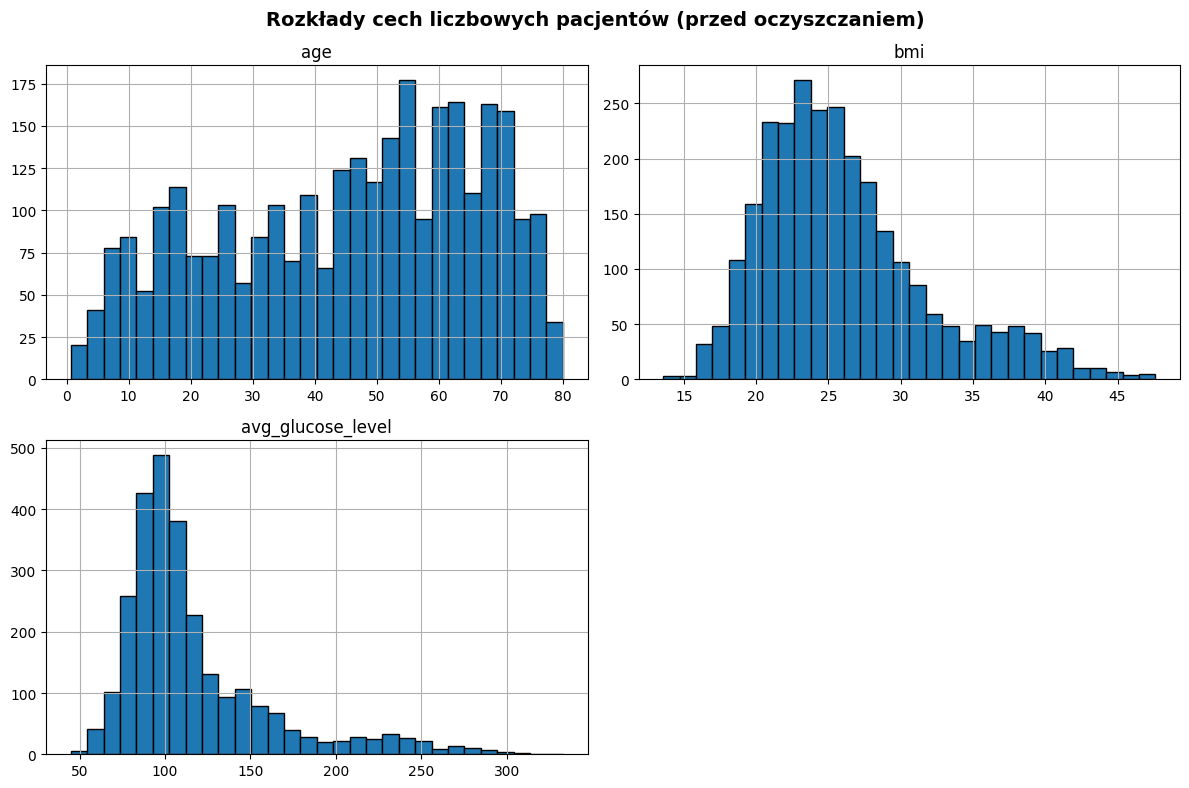

In [17]:
# TODO: ponownie statystyki opisowe i histogramy — co się zmieniło?
# Odp: Tym razem histogramy bliżej przypominają rozkład normalny bez dziwnych skrajnych wartości.

# TODO: statystyki opisowe
print("Statystyki opisowe dla wybranych cech:")
display(pacjenci[LICZBOWE].describe())

# TODO: histogramy (np. pacjenci[LICZBOWE].hist(...))
pacjenci[LICZBOWE].hist(bins=30, figsize=(12, 8), edgecolor='black', grid=True)
plt.suptitle("Rozkłady cech liczbowych pacjentów (przed oczyszczaniem)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

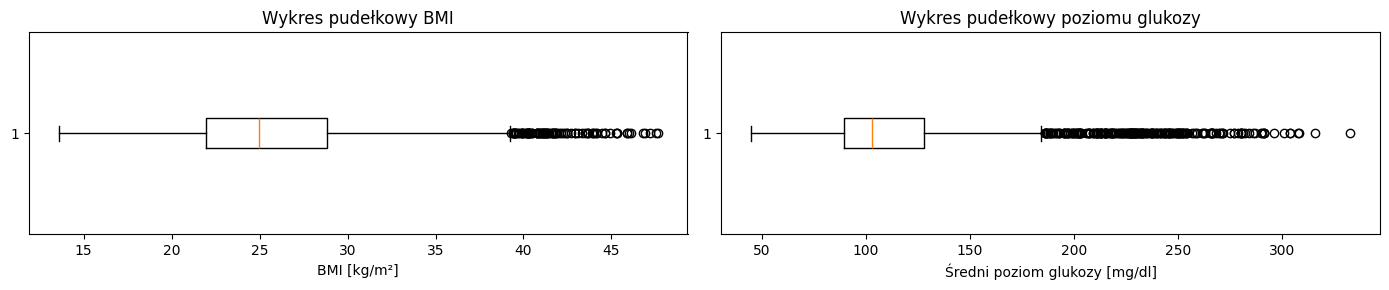

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))

# TODO: wykresy pudełkowe bmi i glukozy
axes[0].boxplot(pacjenci['bmi'].dropna(), vert=False)
axes[0].set_title("Wykres pudełkowy BMI")
axes[0].set_xlabel("BMI [kg/m²]")

axes[1].boxplot(pacjenci['avg_glucose_level'].dropna(), vert=False)
axes[1].set_title("Wykres pudełkowy poziomu glukozy")
axes[1].set_xlabel("Średni poziom glukozy [mg/dl]")

plt.tight_layout()
plt.show()

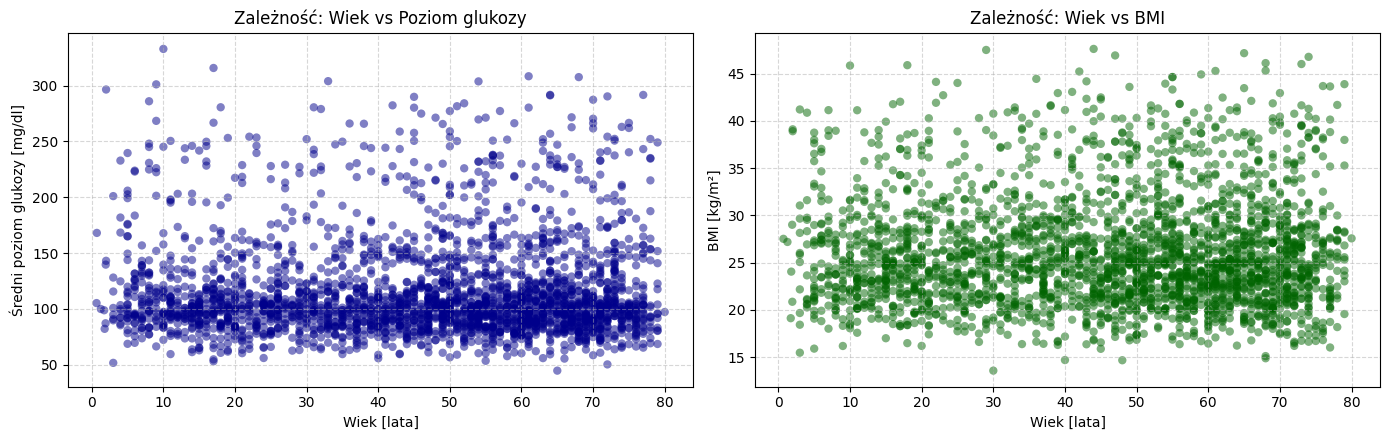

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# TODO: wykresy punktowe age × glukoza i age × bmi
axes[0].scatter(pacjenci['age'], pacjenci['avg_glucose_level'], alpha=0.5, color='darkblue', edgecolor='none')
axes[0].set_title("Zależność: Wiek vs Poziom glukozy")
axes[0].set_xlabel("Wiek [lata]")
axes[0].set_ylabel("Średni poziom glukozy [mg/dl]")
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].scatter(pacjenci['age'], pacjenci['bmi'], alpha=0.5, color='darkgreen', edgecolor='none')
axes[1].set_title("Zależność: Wiek vs BMI")
axes[1].set_xlabel("Wiek [lata]")
axes[1].set_ylabel("BMI [kg/m²]")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:* Punkty poza wąsami leżą po prawej stronie pudełka i dla poziomu glukozy jest ich więcej, a przynajmniej tak to wygląda na wykresie. Wysokie wartości glukozy występują w każdym wieku, a wartość 300 mg/dl traktowałbym jako rzadki przypadek, choć nie wykluczam, że to błąd. Nie jestem w stanie tego zweryfikować.

## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [20]:
def maska_iqr(s, k=1.5):
    # TODO
    s_no_nan = s.dropna()
    q1 = s_no_nan.quantile(0.25)
    q3 = s_no_nan.quantile(0.75)
    iqr = q3 - q1
    return ~s.between(q1 - k * iqr, q3 + k * iqr) & s.notna()

def maska_z(s, prog=3):
    # TODO
    s_no_nan = s.dropna()
    mean = s_no_nan.mean()
    std = s_no_nan.std()
    return (abs((s - mean) / std) > prog) & s.notna()

def maska_mad(s, prog=3.5):
    # TODO
    s_no_nan = s.dropna()
    median = s_no_nan.median()
    mad = (s_no_nan - median).abs().median()
    return (abs(0.6745 * (s - median) / mad) > prog) & s.notna()

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [21]:
# TODO: tabela porównawcza `porownanie`

slownik_porownania = {
    "IQR 1.5": [maska_iqr(pacjenci[col], k=1.5).sum() for col in LICZBOWE],
    "IQR 3.0": [maska_iqr(pacjenci[col], k=3.0).sum() for col in LICZBOWE],
    "z-score": [maska_z(pacjenci[col], prog=3).sum() for col in LICZBOWE],
    "MAD": [maska_mad(pacjenci[col], prog=3.5).sum() for col in LICZBOWE],
    "skew": [pacjenci[col].skew() for col in LICZBOWE]
}

porownanie = pd.DataFrame(slownik_porownania, index=LICZBOWE)
porownanie

,IQR 1.5,IQR 3.0,z-score,MAD,skew
age,0,0,0,0,-0.33
bmi,100,0,23,33,0.99
avg_glucose_level,235,81,62,223,1.80


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:*
1. **Wiek (`age`):** Rozkład wieku jest zbliżony do jednostajnego z lekką lewą skośnością (brak wyraźnego ogona czy wartości silnie oddalonych od reszty grupy), dlatego żadna z metod nie klasyfikuje żadnego pacjenta jako odstającego.
2. **Glukoza (`avg_glucose_level`):** Ma silnie prawoskośny rozkład (`skew = 1.80`) z bardzo długim prawym ogonem. Klasyczny z-score jest mało czuły na asymetryczne rozkłady, ponieważ pojedyncze skrajne wartości sztucznie zawyżają średnią i odchylenie standardowe (przez co wykrywa tylko 62 przypadki). Z kolei IQR 1.5 (235) oraz MAD (223) opierają się na miarach odpornych (mediana, kwartyle), które nie dają się łatwo zniekształcić przez ogon rozkładu, dzięki czemu skuteczniej wychwytują te naturalnie występujące wysokie stężenia.

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

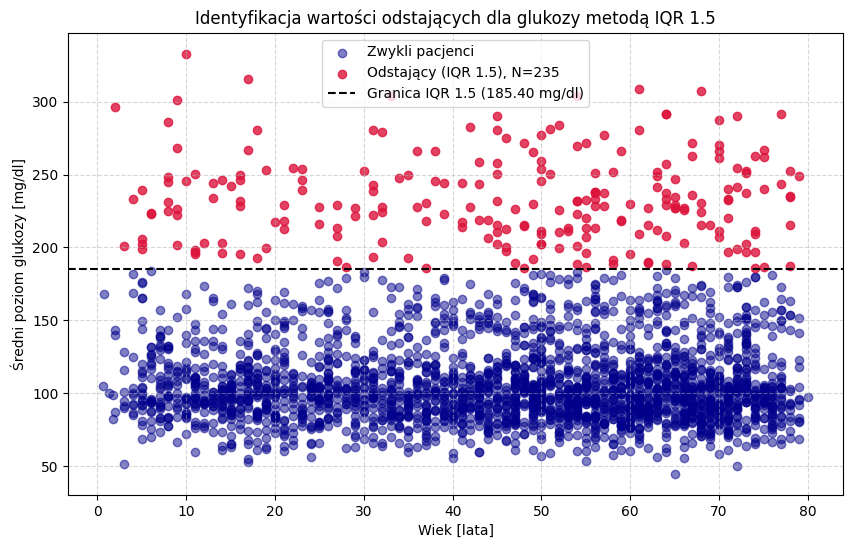

In [22]:
# TODO: wykres punktowy z zaznaczonymi wartościami odstającymi

odstajace_iqr = maska_iqr(pacjenci['avg_glucose_level'], k=1.5)
liczba_odstajacych = odstajace_iqr.sum()

plt.figure(figsize=(10, 6))

# Standardowi pacjenci
plt.scatter(pacjenci.loc[~odstajace_iqr, 'age'],
            pacjenci.loc[~odstajace_iqr, 'avg_glucose_level'],
            alpha=0.5, color='darkblue', label='Zwykli pacjenci')

# Pacjenci odstający
plt.scatter(pacjenci.loc[odstajace_iqr, 'age'],
            pacjenci.loc[odstajace_iqr, 'avg_glucose_level'],
            alpha=0.8, color='crimson', label=f'Odstający (IQR 1.5), N={liczba_odstajacych}')

# Górna granica IQR 1.5
q1 = pacjenci['avg_glucose_level'].quantile(0.25)
q3 = pacjenci['avg_glucose_level'].quantile(0.75)
iqr = q3 - q1
granica_gora = q3 + 1.5 * iqr

plt.axhline(granica_gora, color='black', linestyle='--', linewidth=1.5, label=f'Granica IQR 1.5 ({granica_gora:.2f} mg/dl)')

plt.title("Identyfikacja wartości odstających dla glukozy metodą IQR 1.5")
plt.xlabel("Wiek [lata]")
plt.ylabel("Średni poziom glukozy [mg/dl]")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

Odsetek udarów wśród pacjentów z glukozą odstającą (N=235): 21.70%
Odsetek udarów wśród pozostałych pacjentów (N=2765): 21.92%


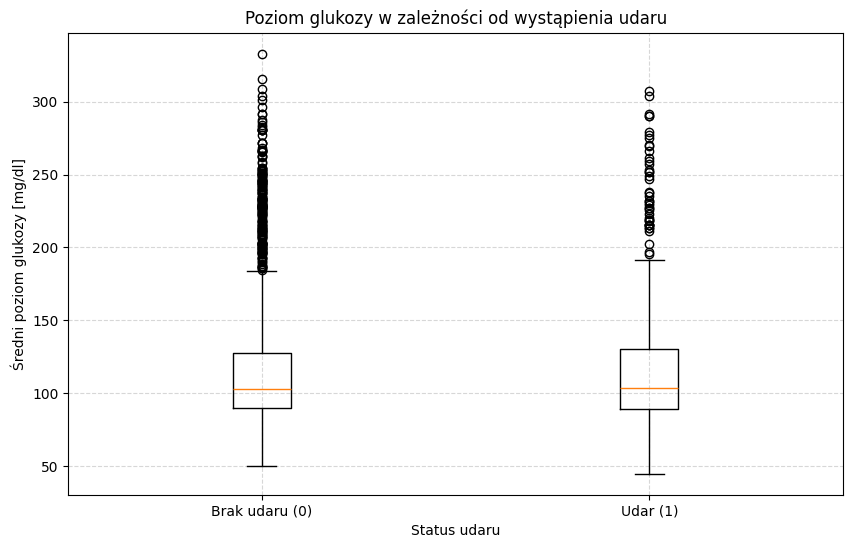

In [31]:
# TODO: odsetek udarów w obu grupach
odstajace_iqr = maska_iqr(pacjenci['avg_glucose_level'], k=1.5)
stroke_odstajace = pacjenci.loc[odstajace_iqr, 'stroke']
stroke_pozostale = pacjenci.loc[~odstajace_iqr, 'stroke']

odsetek_odstajace = stroke_odstajace.mean() * 100
odsetek_pozostale = stroke_pozostale.mean() * 100

print(f"Odsetek udarów wśród pacjentów z glukozą odstającą (N={len(stroke_odstajace)}): {odsetek_odstajace:.2f}%")
print(f"Odsetek udarów wśród pozostałych pacjentów (N={len(stroke_pozostale)}): {odsetek_pozostale:.2f}%")

# TODO: boxplot glukozy w podziale na stroke
plt.figure(figsize=(10, 6))

# Grupujemy poziom glukozy pacjentów względem tego, czy mieli udar (stroke = 0 vs stroke = 1)
pacjenci_do_wykresu = [pacjenci.loc[pacjenci['stroke'] == 0, 'avg_glucose_level'].dropna(),
                       pacjenci.loc[pacjenci['stroke'] == 1, 'avg_glucose_level'].dropna()]

plt.boxplot(pacjenci_do_wykresu, tick_labels=['Brak udaru (0)', 'Udar (1)'])
plt.title("Poziom glukozy w zależności od wystąpienia udaru")
plt.xlabel("Status udaru")
plt.ylabel("Średni poziom glukozy [mg/dl]")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

```markdown
✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:* Z analizy wynika, że odsetek udarów wśród pacjentów z "odstającą" glukozą (21.70%) jest niemal identyczny jak u pozostałych pacjentów (21.92%). Któraś z tych wartości jest na pewno nieprawidłowa, natomiast nie mam wystarczająco danych, by to adekwatnie określić. Usunięcie danych pacjentów z wysoką glukozą na tym etapie wydaje się kontrproduktywne.
```

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [32]:
# TODO: tabela krzyżowa
tabela_krzyzowa = pd.crosstab(pacjenci['work_type'], pacjenci['smoking_status'])
display(tabela_krzyzowa)

# TODO: maski
dziecko_pali = (pacjenci['work_type'] == 'children') & (pacjenci['smoking_status'].isin(['smokes', 'formerly smoked']))
maluch_student = (pacjenci['age'] <= 3) & (pacjenci['work_type'] == 'student')

print(f"Liczba dzieci, które palą/paliły: {dziecko_pali.sum()}")
print(f"Liczba maluchów (<=3 lata) będących studentami: {maluch_student.sum()}")

print("\nPrzykładowe dzieci, które palą/paliły:")
display(pacjenci[dziecko_pali].head())

print("\nPrzykładowe maluchy-studenci:")
display(pacjenci[maluch_student].head())

smoking_status,Unknown,formerly smoked,never smoked,smokes
work_type,,,,
Govt_job,16,63,94,67
Never_worked,1,30,36,35
Private,76,440,585,445
Self-employed,18,137,166,131
children,17,0,274,15
student,22,67,190,75


Liczba dzieci, które palą/paliły: 15
Liczba maluchów (<=3 lata) będących studentami: 1

Przykładowe dzieci, które palą/paliły:


,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
111,A678646,Female,9.00,0,0,False,children,Rural,96.59,22.24,smokes,0
290,A844121,Male,13.00,0,0,False,children,Urban,163.31,20.14,smokes,0
336,A135365,Female,12.00,0,0,False,children,Urban,135.59,27.15,smokes,0
352,A810636,Male,14.00,0,0,False,children,Rural,203.26,NaN,smokes,0
361,A843508,Male,2.00,0,0,False,children,Urban,143.14,39.11,smokes,0



Przykładowe maluchy-studenci:


,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
52,A582477,Female,1.80,0,0,False,student,Rural,82.20,24.05,formerly smoked,0


✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:* Moim zdaniem nie wykryłby, ponieważ te narzędzia wykrywają przypadki na pojedynczych kolumnach, a nie na skrzyżowaniach kolumn.

## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [33]:
from scipy.stats import chi2

X = pacjenci[LICZBOWE].dropna()
Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)
prog = chi2.ppf(0.99, df=len(LICZBOWE))
odstajacy_d2 = d2 > prog

print(f"Próg odległości d2 (chi-square 0.99, df=3): {prog:.2f}")
print(f"Liczba pacjentów przekraczających próg: {odstajacy_d2.sum()}")

jezeli_odstajacy = Z.loc[odstajacy_d2]
index_max_udzialu = (jezeli_odstajacy ** 2).idxmax(axis=1)

print("\nUdział cech w generowaniu anomalii (najczęściej dominująca cecha):")
print(index_max_udzialu.value_counts())

print("\nPrzykładowi pacjenci o najwyższej odległości d2:")
display(pacjenci.loc[index_max_udzialu.index].join(d2.rename('d2_distance')).sort_values(by='d2_distance', ascending=False).head())

Próg odległości d2 (chi-square 0.99, df=3): 11.34
Liczba pacjentów przekraczających próg: 73

Udział cech w generowaniu anomalii (najczęściej dominująca cecha):
avg_glucose_level    54
bmi                  19
Name: count, dtype: int64

Przykładowi pacjenci o najwyższej odległości d2:


,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke,d2_distance
708,A133131,Male,10.00,0,0,False,children,Urban,332.91,18.52,never smoked,0,27.66
680,A303593,Female,2.00,0,0,False,children,Rural,296.55,38.91,never smoked,0,25.15
605,A856534,Male,9.00,0,0,False,children,Urban,301.18,16.18,never smoked,0,22.75
2956,A823092,Male,77.00,1,0,True,Private,Urban,291.70,38.82,formerly smoked,0,22.19
859,A122946,Male,17.00,0,0,False,Private,Rural,315.84,26.12,never smoked,0,21.43


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

Liczba odstających przed transformacją: 73
Liczba odstających po zlogarytmowaniu glukozy: 31


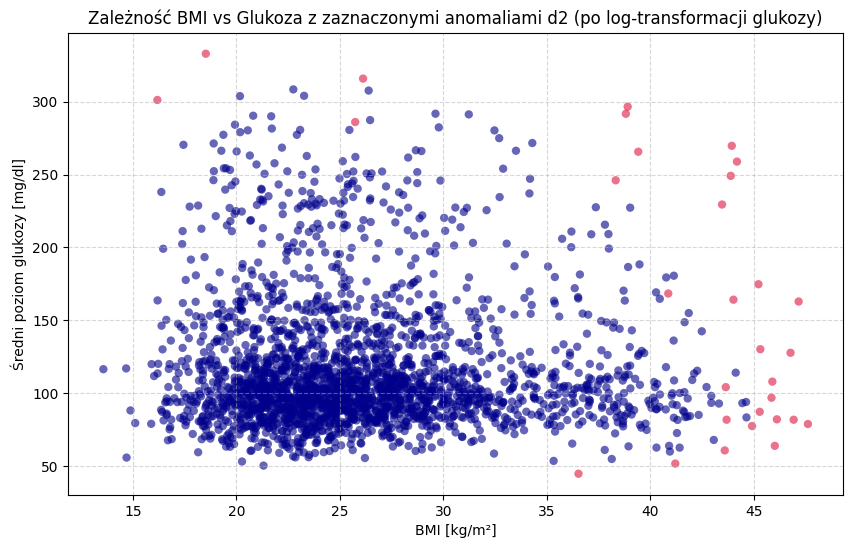

,age,bmi,avg_glucose_level
age,1.00,0.02,0.01
bmi,0.02,1.00,-0.02
avg_glucose_level,0.01,-0.02,1.00


In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

# TODO: X_log, Z_log, d2_log i liczba odstających
X_log = pacjenci[LICZBOWE].dropna().copy()
X_log['avg_glucose_level'] = np.log(X_log['avg_glucose_level'])

Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log ** 2).sum(axis=1)
prog_log = chi2.ppf(0.99, df=len(LICZBOWE))
odstajacy_d2_log = d2_log > prog_log

print(f"Liczba odstających przed transformacją: {odstajacy_d2.sum()}")
print(f"Liczba odstających po zlogarytmowaniu glukozy: {odstajacy_d2_log.sum()}")

# TODO: wykres punktowy
plt.figure(figsize=(10, 6))
plt.scatter(pacjenci.loc[Z_log.index, 'bmi'], pacjenci.loc[Z_log.index, 'avg_glucose_level'],
            c=np.where(odstajacy_d2_log, 'crimson', 'darkblue'), alpha=0.6, edgecolors='none')
plt.title("Zależność BMI vs Glukoza z zaznaczonymi anomaliami d2 (po log-transformacji glukozy)")
plt.xlabel("BMI [kg/m²]")
plt.ylabel("Średni poziom glukozy [mg/dl]")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

display(X.corr())

`✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:* Nie, odległość Mahalanobisa nie dałaby w tym przypadku istotnych korzyści. Odległość Mahalanobisa różni się od standaryzowanej odległości euklidesowej tym, że uwzględnia kowariancję (korelację) między cechami, eliminując efekty współliniowości. Kiedy zmienne są nieskorelowane (macierz kowariancji jest diagonalna), odległość Mahalanobisa upraszcza się bezpośrednio do standaryzowanej odległości euklidesowej (czyli sumy kwadratów Z-score'ów, którą właśnie policzyliśmy). Z tego powodu zastosowanie metody Mahalanobisa dałoby niemal identyczne wyniki.


### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [27]:
# TODO (dla chętnych)


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [36]:
# TODO: ramka flagi
flagi = pd.DataFrame(index=oryginal.index)

flagi['niemozliwa_wartosc'] = zle_bmi | zla_glukoza | zly_wiek

flagi['glukoza_iqr'] = maska_iqr(pacjenci['avg_glucose_level'], k=1.5)

flagi['nielogiczna_kategoria'] = dziecko_pali | maluch_student

flagi['odlegly_od_srodka'] = odstajacy_d2_log.reindex(oryginal.index, fill_value=False)

print("Liczba pacjentów z poszczególnymi flagami:")
print(flagi.sum())

co_najmniej_jedna = flagi.any(axis=1).sum()
print(f"\nŁączna liczba pacjentów z co najmniej jedną flagą: {co_najmniej_jedna} (na {len(oryginal)} pacjentów)")

Liczba pacjentów z poszczególnymi flagami:
niemozliwa_wartosc       560
glukoza_iqr              235
nielogiczna_kategoria     16
odlegly_od_srodka         31
dtype: int64

Łączna liczba pacjentów z co najmniej jedną flagą: 806 (na 3000 pacjentów)


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | NaN | wartości niemożliwe są ewidentnie wszystkie błędne, więc nie ma sensu ich wykorzystywać |
| wysoka glukoza (IQR) | zostawić | w populacji na pewno istnieją osoby z wysoką glukozą, a ja na ten moment nie wiem, które z danych w tym zbiorze mogą być błędne |
| nielogiczne kategorie | flaga | wydaje mi się, że przyjęte skrzyżowania kolumn nie muszą być koniecznie niemożliwe, lecz po prostu bardzo nietypowe i mało prawdopodobne, a liczby tych wartości nie są też statystycznie zauważalne, więc nie powinny zauważalnie zaburzać innych analiz |
| odlegli od środka | flaga | nie mam w żadnym stopniu pewności, że te dane są nieprawidłowe, natomiast są wystarczająco nietypowe, że ich oflagowanie może być przydatne |